In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.utils.db import get_engine
engine = get_engine()
def q(sql): 
    with engine.connect() as conn: return pd.read_sql(text(sql), conn)

from src.analysis.event_study import fetch_daily, event_study

In [2]:
GROUPS = """CASE WHEN carrier_code = 'DL' THEN 'Delta (DL)'
              WHEN carrier_code = '9E' THEN 'Endeavor Air (9E, Delta Connection)'
              ELSE 'All other airlines' END"""

daily = fetch_daily(q, "2024-06-01", "2024-08-15", GROUPS)
ev, summary = event_study(daily, "2024-07-19", "2024-08-05")
summary

,group,baseline_rate,peak_rate,peak_date,recovery_date,days_to_recover,excess_flights
0,All other airlines,1.56,10.9,2024-07-19,2024-07-21,2,2317
1,Delta (DL),0.16,47.4,2024-07-21,2024-07-25,6,5753
2,"Endeavor Air (9E, Delta Connection)",2.83,49.0,2024-07-19,2024-07-24,5,670


In [3]:
for tol in (0.5, 1.0, 2.0):
    _, s = event_study(daily, "2024-07-19", "2024-08-05", tolerance_pts=tol)
    print(f"tolerance {tol} pts")
    print(s[["group", "recovery_date", "days_to_recover"]].to_string(index=False), "\n")

tolerance 0.5 pts
                              group recovery_date  days_to_recover
                 All other airlines    2024-07-21                2
                         Delta (DL)    2024-07-25                6
Endeavor Air (9E, Delta Connection)    2024-07-24                5 

tolerance 1.0 pts
                              group recovery_date  days_to_recover
                 All other airlines    2024-07-21                2
                         Delta (DL)    2024-07-25                6
Endeavor Air (9E, Delta Connection)    2024-07-24                5 

tolerance 2.0 pts
                              group recovery_date  days_to_recover
                 All other airlines    2024-07-21                2
                         Delta (DL)    2024-07-24                5
Endeavor Air (9E, Delta Connection)    2024-07-24                5 



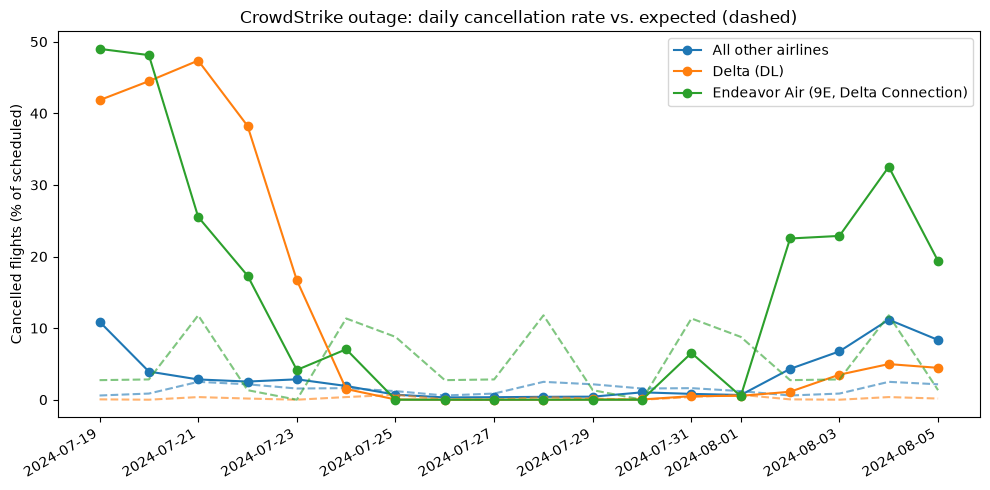

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for grp, g in ev.groupby("grp"):
    g = g.sort_values("full_date")
    (line,) = ax.plot(g["full_date"], g["cancel_rate"], marker="o", label=grp)
    ax.plot(g["full_date"], g["expected_rate"], linestyle="--", color=line.get_color(), alpha=0.6)
ax.set_ylabel("Cancelled flights (% of scheduled)")
ax.set_title("CrowdStrike outage: daily cancellation rate vs. expected (dashed)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(ROOT / "docs" / "event_study_crowdstrike.png", dpi=150)
plt.show()

In [5]:
daily_all = q("""
SELECT full_date, day_of_week,
       COUNT(*)                             AS scheduled,
       COUNT(*) FILTER (WHERE is_cancelled) AS cancelled
FROM analytics.v_flights
GROUP BY 1, 2 ORDER BY 1
""")
daily_all["full_date"] = pd.to_datetime(daily_all["full_date"])
daily_all["cancel_rate"] = 100.0 * daily_all["cancelled"] / daily_all["scheduled"]

def robust_z(series: pd.Series, window: int = 9) -> pd.Series:
    med = series.rolling(window, center=True, min_periods=5).median()
    mad = (series - med).abs().rolling(window, center=True, min_periods=5).median()
    return (series - med) / (1.4826 * mad.clip(lower=0.1))

Z_THRESHOLD = 4
daily_all["z"] = daily_all.groupby("day_of_week")["cancel_rate"].transform(robust_z)

flagged = daily_all[daily_all["z"] >= Z_THRESHOLD].sort_values("full_date").copy()
flagged["event_id"] = (flagged["full_date"].diff().dt.days.fillna(99) > 2).cumsum()

events = (flagged.groupby("event_id")
          .agg(start=("full_date", "min"), end=("full_date", "max"),
               days=("full_date", "size"),
              peak_cancel_rate=("cancel_rate", "max"), peak_z=("z", "max"))
          .reset_index(drop=True)
          .sort_values("peak_z", ascending=False))
events

,start,end,days,peak_cancel_rate,peak_z
38,2025-11-08,2025-11-13,6,12.131885,61.852644
15,2024-10-08,2024-10-11,4,9.410836,47.547538
10,2024-08-02,2024-08-06,4,10.844116,42.425987
8,2024-07-17,2024-07-20,4,16.526924,33.492944
19,2025-01-05,2025-01-10,5,15.979410,31.093075
14,2024-09-26,2024-09-27,2,5.294202,28.750298
7,2024-05-28,2024-06-01,3,5.360444,27.551371
5,2024-04-20,2024-04-20,1,4.008611,18.895865
17,2024-11-08,2024-11-08,1,4.497955,13.961682
20,2025-01-21,2025-01-22,2,10.159661,12.923183
